# Data cleaning

In [1]:
import ast

import pandas as pd

DATA = 'data'

movies   = pd.read_csv(f'{DATA}/movies_metadata.csv', low_memory=False)
credits  = pd.read_csv(f'{DATA}/credits.csv')
keywords = pd.read_csv(f'{DATA}/keywords.csv')
links    = pd.read_csv(f'{DATA}/links.csv')
ratings  = pd.read_csv(f'{DATA}/ratings.csv',
                       dtype={'userId': 'int32', 'movieId': 'int32', 'rating': 'float32', 'timestamp': 'int64'})

rows_before = {'movies': len(movies), 'credits': len(credits), 'keywords': len(keywords),
               'links': len(links), 'ratings': len(ratings)}
deleted = {}
edited = {}

for name, n in rows_before.items():
    print(f'Loaded {n:,} rows from {name}')

Loaded 45,466 rows from movies
Loaded 45,476 rows from credits
Loaded 46,419 rows from keywords
Loaded 45,843 rows from links
Loaded 26,024,289 rows from ratings


## Movies: broken rows
3 movies are split over two rows. Both halves are removed.

In [2]:
before = len(movies)
bad_idx = movies.index[~movies['id'].astype(str).str.fullmatch(r'\d+')]
movies = movies.drop(index=list(bad_idx) + list(bad_idx - 1))

deleted['Movies: broken rows'] = before - len(movies)
print(f"Deleted {deleted['Movies: broken rows']:,} rows")
print(f'Rows in movies: {len(movies):,}')

Deleted 6 rows
Rows in movies: 45,460


## Movies: data types
Convert text columns to numbers, dates and booleans.

In [3]:
movies['id'] = movies['id'].astype('int64')
movies['budget'] = pd.to_numeric(movies['budget'])
movies['popularity'] = pd.to_numeric(movies['popularity'])
movies['release_date'] = pd.to_datetime(movies['release_date'], errors='coerce')
movies['vote_count'] = movies['vote_count'].astype('Int64')
to_bool = {'True': True, 'False': False, True: True, False: False}
movies['adult'] = movies['adult'].map(to_bool).astype('boolean')
movies['video'] = movies['video'].map(to_bool).astype('boolean')

edited['Movies: data types'] = len(movies)
print(f"Edited {len(movies):,} rows (id, budget, popularity, vote_count -> numbers, release_date -> datetime, adult, video -> bool)")
print(movies[['id', 'budget', 'popularity', 'vote_count', 'release_date', 'adult', 'video']].dtypes.to_string())

Edited 45,460 rows (id, budget, popularity, vote_count -> numbers, release_date -> datetime, adult, video -> bool)
id                       int64
budget                   int64
popularity             float64
vote_count               Int64
release_date    datetime64[ns]
adult                  boolean
video                  boolean


## Movies: duplicates
Remove exact copies. For other duplicated ids, keep the row with the most votes. Must run before parsing nested columns.

In [4]:
before = len(movies)
movies = movies.drop_duplicates()
deleted['Movies: exact duplicates'] = before - len(movies)

before = len(movies)
movies = (movies.sort_values('vote_count', ascending=False)
                .drop_duplicates('id')
                .sort_index())
deleted['Movies: duplicate ids'] = before - len(movies)

print(f"Deleted {deleted['Movies: exact duplicates']:,} exact duplicates and {deleted['Movies: duplicate ids']:,} duplicate ids")
print(f'Rows in movies: {len(movies):,} | ids still duplicated: {movies["id"].duplicated().sum()}')

Deleted 17 exact duplicates and 13 duplicate ids
Rows in movies: 45,430 | ids still duplicated: 0


## Movies: unknown values
0 in budget, revenue and runtime means unknown, so set to missing.

In [5]:
UNKNOWN_IF_ZERO = ['budget', 'revenue', 'runtime']

changed = 0
zeros_per_col = {}
for col in UNKNOWN_IF_ZERO:
    zeros = movies[col] == 0
    print(f'  {col:8s} {zeros.sum():>7,} zeros -> missing')
    changed |= zeros
    zeros_per_col[col] = int(zeros.sum())
    movies[col] = movies[col].mask(zeros).astype('float64')

edited['Movies: unknown values'] = int(changed.sum())
print(f"Edited {edited['Movies: unknown values']:,} rows")

  budget    36,550 zeros -> missing
  revenue   38,032 zeros -> missing
  runtime    1,558 zeros -> missing
Edited 40,066 rows


## Movies: unrealistic budgets and revenues
Budgets and revenues under $1,000 are set to missing.

In [6]:
MIN_AMOUNT = 1000

# Release years of the movies that get a value set to unknown here
low_budget = movies['budget'] < MIN_AMOUNT
low_revenue = movies['revenue'] < MIN_AMOUNT
years = movies['release_date'].dt.year
for name, mask in [('budget', low_budget), ('revenue', low_revenue), ('budget and/or revenue', low_budget | low_revenue)]:
    y = years[mask]
    print(f'{name}: {mask.sum()} movies | {y.min():.0f}-{y.max():.0f} | median {y.median():.0f} | '
          f'before 1950: {(y < 1950).sum()} | 2000 or later: {(y >= 2000).sum()}')
print('Per decade (budget and/or revenue):', (years[low_budget | low_revenue].dropna() // 10 * 10).astype(int).value_counts().sort_index().astype(int).to_dict())
print()

for col in ['budget', 'revenue']:
    too_low = movies[col] < MIN_AMOUNT   # missing values are not counted
    print(f'{col}: {too_low.sum():,} below ${MIN_AMOUNT:,} | examples: {movies.loc[too_low, col].value_counts().head(6).to_dict()}')
    first = movies[too_low].sort_values('release_date').iloc[0]
    print(f"  earliest: {first['title']} ({first['release_date'].date()}), ${first[col]:,.0f}")
    movies.loc[too_low, col] = None
    edited[f'Movies: {col} < $1,000'] = int(too_low.sum())

print(f"Edited {edited['Movies: budget < $1,000']:,} budgets and {edited['Movies: revenue < $1,000']:,} revenues")

budget: 244 movies | 1903-2016 | median 2006 | before 1950: 27 | 2000 or later: 158
revenue: 154 movies | 1923-2017 | median 2001 | before 1950: 8 | 2000 or later: 84
budget and/or revenue: 355 movies | 1903-2017 | median 2005 | before 1950: 31 | 2000 or later: 221
Per decade (budget and/or revenue): {1900: 2, 1910: 2, 1920: 5, 1930: 12, 1940: 10, 1950: 5, 1960: 13, 1970: 14, 1980: 16, 1990: 53, 2000: 101, 2010: 120}

budget: 244 below $1,000 | examples: {1.0: 25, 2.0: 14, 10.0: 10, 3.0: 9, 5.0: 8, 500.0: 8}
  earliest: The Great Train Robbery (1903-12-01), $150
revenue: 154 below $1,000 | examples: {1.0: 12, 3.0: 9, 15.0: 5, 8.0: 5, 5.0: 5, 25.0: 4}
  earliest: Safety Last! (1923-04-01), $623
Edited 244 budgets and 154 revenues


In [7]:
# Earliest movies with a known budget and revenue after the cleaning
print('Earliest movie in the data:', movies['release_date'].min().date())
for col in ['budget', 'revenue']:
    known = movies[movies[col].notna() & movies['release_date'].notna()].sort_values('release_date')
    first = known.iloc[0]
    print(f"\nFirst known {col}: {first['title']} ({first['release_date'].date()}), ${first[col]:,.0f}")
    print(known[['title', 'release_date', col]].head(3).to_string(index=False))

Earliest movie in the data: 1874-12-09

First known budget: A Trip to the Moon (1902-09-01), $5,985
                                                   title release_date  budget
                                      A Trip to the Moon   1902-09-01  5985.0
                                   The Impossible Voyage   1904-10-01  7500.0
The Dinosaur and the Missing Link: A Prehistoric Tragedy   1915-01-01  5000.0

First known revenue: The Birth of a Nation (1915-02-08), $11,000,000
                       title release_date    revenue
       The Birth of a Nation   1915-02-08 11000000.0
                   The Cheat   1915-12-13   137365.0
20,000 Leagues Under the Sea   1916-12-24  8000000.0


## Movies: nested columns
Parse text into lists/dicts.

In [8]:
NESTED_COLS = ['genres', 'production_companies', 'production_countries', 'spoken_languages', 'belongs_to_collection']

def parse(x):
    return ast.literal_eval(x) if isinstance(x, str) else None

for col in NESTED_COLS:
    movies[col] = movies[col].apply(parse)

edited['Movies: nested columns'] = len(movies)
print(f'Parsed {len(NESTED_COLS)} columns in {len(movies):,} rows')

Parsed 5 columns in 45,430 rows


## Credits: duplicates
Remove exact copies, then keep one row per id.

In [9]:
before = len(credits)
credits = credits.drop_duplicates()
deleted['Credits: exact duplicates'] = before - len(credits)

before = len(credits)
credits = credits.drop_duplicates('id')
deleted['Credits: duplicate ids'] = before - len(credits)

print(f"Deleted {deleted['Credits: exact duplicates']:,} exact duplicates and {deleted['Credits: duplicate ids']:,} duplicate ids")
print(f'Rows in credits: {len(credits):,}')

Deleted 37 exact duplicates and 7 duplicate ids
Rows in credits: 45,432


## Credits: nested columns

In [10]:
credits['cast'] = credits['cast'].apply(ast.literal_eval)
credits['crew'] = credits['crew'].apply(ast.literal_eval)

edited['Credits: nested columns'] = len(credits)
print(f'Parsed cast and crew in {len(credits):,} rows')

Parsed cast and crew in 45,432 rows


## Keywords: duplicates
All duplicates are exact copies. Keep one row per id.

In [11]:
before = len(keywords)
keywords = keywords.drop_duplicates('id')

deleted['Keywords: duplicate ids'] = before - len(keywords)
print(f"Deleted {deleted['Keywords: duplicate ids']:,} rows")
print(f'Rows in keywords: {len(keywords):,}')

Deleted 987 rows
Rows in keywords: 45,432


## Keywords: nested column

In [12]:
keywords['keywords'] = keywords['keywords'].apply(ast.literal_eval)

edited['Keywords: nested column'] = len(keywords)
print(f'Parsed keywords in {len(keywords):,} rows')

Parsed keywords in 45,432 rows


## Links
Remove links without a `tmdbId` or whose `tmdbId` is not in movies.

In [13]:
movie_ids = set(movies['id'])

before = len(links)
links = links.dropna(subset=['tmdbId'])
deleted['Links: missing tmdbId'] = before - len(links)
links['tmdbId'] = links['tmdbId'].astype('int64')

before = len(links)
links = links[links['tmdbId'].isin(movie_ids)]
deleted['Links: tmdbId not in movies'] = before - len(links)

print(f"Deleted {deleted['Links: missing tmdbId']:,} rows without tmdbId and {deleted['Links: tmdbId not in movies']:,} not found in movies")
print(f"Duplicated movieId: {links['movieId'].duplicated().sum()} | tmdbId shared by several movieIds: {links['tmdbId'].duplicated().sum()}")
print(f'Rows in links: {len(links):,}')

Deleted 219 rows without tmdbId and 164 not found in movies
Duplicated movieId: 0 | tmdbId shared by several movieIds: 30
Rows in links: 45,460


## Ratings
Add `movie_id` (the movie's `id`) through links, remove ratings without a movie, and convert `timestamp` to datetime.

In [14]:
print('Missing values:', int(ratings.isna().sum().sum()),
      '| same user rating same movie twice:', ratings.duplicated(['userId', 'movieId']).sum())

ratings['movie_id'] = ratings['movieId'].map(links.set_index('movieId')['tmdbId'])

before = len(ratings)
ratings = ratings.dropna(subset=['movie_id'])
deleted['Ratings: no matching movie'] = before - len(ratings)
ratings['movie_id'] = ratings['movie_id'].astype('int64')

ratings['timestamp'] = pd.to_datetime(ratings['timestamp'], unit='s')
edited['Ratings: movie_id + datetime'] = len(ratings)

print(f"Deleted {deleted['Ratings: no matching movie']:,} ratings without a matching movie")
print(f'Rows in ratings: {len(ratings):,} | users: {ratings["userId"].nunique():,} | movies: {ratings["movie_id"].nunique():,}')
ratings.head(3)

Missing values: 0 | same user rating same movie twice: 0


Deleted 42,722 ratings without a matching movie


Rows in ratings: 25,981,567 | users: 270,883 | movies: 44,708


,userId,movieId,rating,timestamp,movie_id
0,1,110,1.0,2015-03-09 22:52:09,197
1,1,147,4.5,2015-03-09 23:07:15,10474
2,1,858,5.0,2015-03-09 22:52:03,238


## Prepare for MongoDB
Turn missing values into `None` so they are stored as null. Ratings are converted in batches.

In [15]:
def to_documents(df):
    # Plain Python objects, with every missing value as None
    return df.astype(object).where(df.notna(), None).to_dict('records')

def batches(df, size=100_000):
    for start in range(0, len(df), size):
        yield to_documents(df.iloc[start:start + size])

movie_docs   = to_documents(movies)
credit_docs  = to_documents(credits)
keyword_docs = to_documents(keywords)

def has_nan(docs):
    return sum(isinstance(v, float) and v != v for d in docs for v in d.values())

for name, docs in [('movies', movie_docs), ('credits', credit_docs), ('keywords', keyword_docs)]:
    print(f'{name:9s} {len(docs):>7,} documents | NaN left: {has_nan(docs)}')
print('ratings  ', f'{len(ratings):,} rows, missing values: {int(ratings.isna().sum().sum())} (converted in batches of 100,000)')

print('\nExample movie with unknown values:')
example = next(d for d in movie_docs if d['budget'] is None and d['release_date'] is None)
print({k: example[k] for k in ['id', 'title', 'budget', 'revenue', 'runtime', 'release_date', 'vote_count', 'adult']})

movies     45,430 documents | NaN left: 0
credits    45,432 documents | NaN left: 0
keywords   45,432 documents | NaN left: 0


ratings   25,981,567 rows, missing values: 0 (converted in batches of 100,000)

Example movie with unknown values:
{'id': 365371, 'title': 'War Stories Our Mother Never Told Us', 'budget': None, 'revenue': None, 'runtime': 95.0, 'release_date': None, 'vote_count': 0, 'adult': False}


## Summary

In [16]:
rows_after = {'movies': len(movies), 'credits': len(credits), 'keywords': len(keywords),
              'links': len(links), 'ratings': len(ratings)}
print(f"{'':10} {'before':>11} {'after':>11}")
for name in rows_before:
    print(f'{name:10} {rows_before[name]:>11,} {rows_after[name]:>11,}')

print('\nDeleted')
for step, n in deleted.items():
    print(f'  {step:<30} {n:>11,}')
print('\nEdited')
for step, n in edited.items():
    print(f'  {step:<30} {n:>11,}')

                before       after
movies          45,466      45,430
credits         45,476      45,432
keywords        46,419      45,432
links           45,843      45,460
ratings     26,024,289  25,981,567

Deleted
  Movies: broken rows                      6
  Movies: exact duplicates                17
  Movies: duplicate ids                   13
  Credits: exact duplicates               37
  Credits: duplicate ids                   7
  Keywords: duplicate ids                987
  Links: missing tmdbId                  219
  Links: tmdbId not in movies            164
  Ratings: no matching movie          42,722

Edited
  Movies: data types                  45,460
  Movies: unknown values              40,066
  Movies: budget < $1,000                244
  Movies: revenue < $1,000               154
  Movies: nested columns              45,430
  Credits: nested columns             45,432
  Keywords: nested column             45,432
  Ratings: movie_id + datetime    25,981,567


## Diagrams for the report

In [17]:
import numpy as np
import matplotlib.pyplot as plt

BLUE, ORANGE, AQUA, GREY = '#2a78d6', '#eb6834', '#1baf7a', '#c3c2b7'
INK = '#52514e'
plt.rcParams.update({
    'figure.dpi': 110, 'font.size': 10,
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.edgecolor': '#b9b8b1', 'axes.labelcolor': INK,
    'axes.titlesize': 12, 'axes.titleweight': 'bold', 'axes.titlelocation': 'left',
    'axes.grid': True, 'grid.color': '#e6e5e1', 'grid.linewidth': 0.8, 'axes.axisbelow': True,
    'xtick.color': INK, 'ytick.color': INK, 'legend.frameon': False,
})

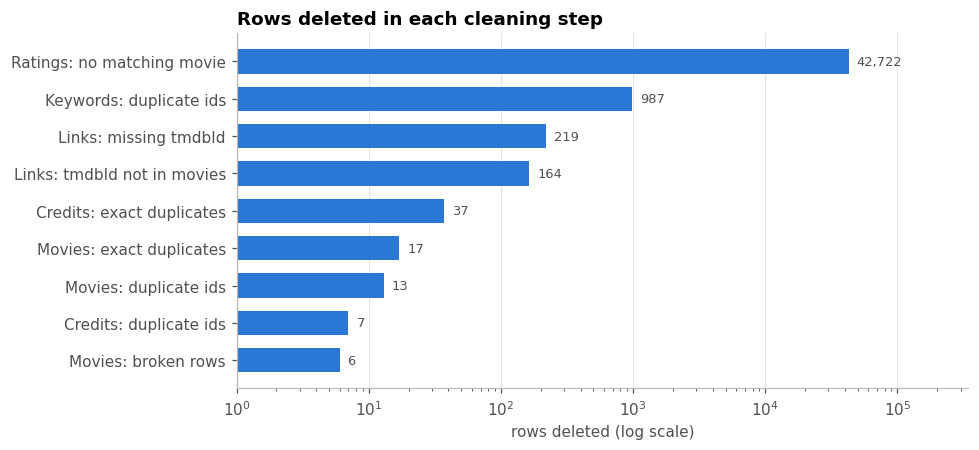

In [18]:
# Rows deleted in each step. Log scale, since the steps range from 6 to over 40,000 rows
steps = pd.Series(deleted).sort_values()

fig, ax = plt.subplots(figsize=(9, 4.2))
ax.barh(steps.index, steps.values, color=BLUE, height=0.65)
for y, v in enumerate(steps.values):
    ax.text(v * 1.15, y, f'{v:,}', va='center', fontsize=8.5, color=INK)
ax.set_xscale('log'); ax.set_xlim(1, steps.max() * 8)
ax.set_title('Rows deleted in each cleaning step'); ax.set_xlabel('rows deleted (log scale)')
ax.grid(axis='y', visible=False)
plt.tight_layout(); plt.show()

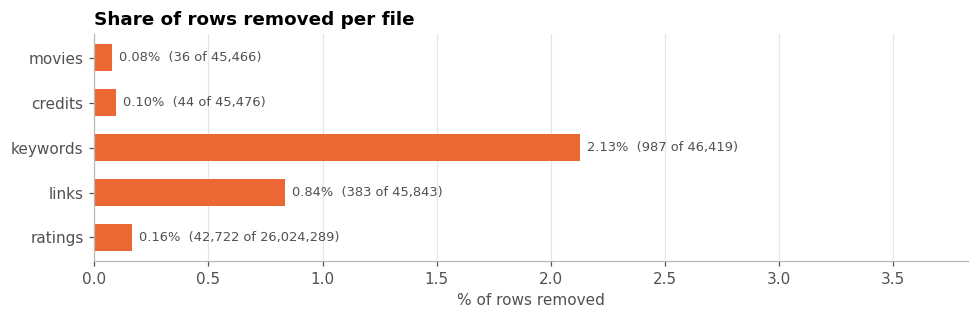

,before,after,removed,%
ratings,26024289,25981567,42722,0.164162
links,45843,45460,383,0.835460
keywords,46419,45432,987,2.126284
credits,45476,45432,44,0.096754
movies,45466,45430,36,0.079180


In [19]:
# Share of each file that was removed
removed = pd.DataFrame({'before': rows_before, 'after': rows_after})
removed['removed'] = removed['before'] - removed['after']
removed['%'] = removed['removed'] / removed['before'] * 100
removed = removed.iloc[::-1]

fig, ax = plt.subplots(figsize=(9, 3))
ax.barh(removed.index, removed['%'], color=ORANGE, height=0.6)
for y, (pct, n, total) in enumerate(zip(removed['%'], removed['removed'], removed['before'])):
    ax.text(pct + 0.03, y, f'{pct:.2f}%  ({n:,} of {total:,})', va='center', fontsize=8.5, color=INK)
ax.set_xlim(0, removed['%'].max() * 1.8)
ax.set_title('Share of rows removed per file'); ax.set_xlabel('% of rows removed')
ax.grid(axis='y', visible=False)
plt.tight_layout(); plt.show()
removed

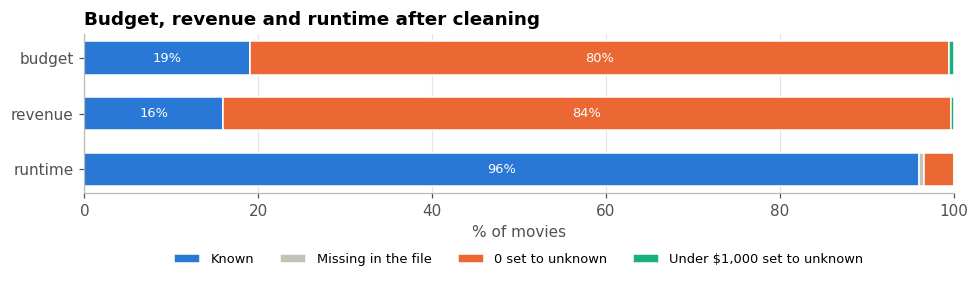

,Known,Missing in the file,0 set to unknown,"Under $1,000 set to unknown"
runtime,43615,257,1558,0
revenue,7244,0,38032,154
budget,8636,0,36550,244


In [20]:
# Known and unknown values after cleaning, split by why the value is unknown
rows = {}
for col in UNKNOWN_IF_ZERO:
    zero = zeros_per_col[col]
    low = edited.get(f'Movies: {col} < $1,000', 0)
    known = int(movies[col].notna().sum())
    rows[col] = {'Known': known,
                 'Missing in the file': len(movies) - known - zero - low,
                 '0 set to unknown': zero,
                 'Under $1,000 set to unknown': low}
status = pd.DataFrame(rows).T.iloc[::-1]
pct = status.div(status.sum(axis=1), axis=0) * 100

fig, ax = plt.subplots(figsize=(9, 2.9))
left = np.zeros(len(pct))
for name, color in zip(pct.columns, [BLUE, GREY, ORANGE, AQUA]):
    ax.barh(pct.index, pct[name], left=left, color=color, label=name, height=0.6, edgecolor='white', linewidth=1)
    for y, (l, v) in enumerate(zip(left, pct[name])):
        if v >= 4:
            ax.text(l + v / 2, y, f'{v:.0f}%', ha='center', va='center', fontsize=8.5, color='white')
    left += pct[name].values
ax.set_xlim(0, 100)
ax.set_title('Budget, revenue and runtime after cleaning'); ax.set_xlabel('% of movies')
ax.grid(axis='y', visible=False)
ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.3), ncol=4, fontsize=8.5)
plt.tight_layout(); plt.show()
status

## Save cleaned data
Save to `data/clean/` as pickle. Use `to_documents`/`batches` before inserting.

In [21]:
import os

OUT = f'{DATA}/clean'
os.makedirs(OUT, exist_ok=True)

for name, df in [('movies', movies), ('credits', credits), ('keywords', keywords), ('links', links), ('ratings', ratings)]:
    path = f'{OUT}/{name}.pkl'
    df.to_pickle(path)
    print(f'Saved {name:9s} {len(df):>11,} rows -> {path} ({os.path.getsize(path) / 1e6:,.0f} MB)')

Saved movies         45,430 rows -> data/clean/movies.pkl (35 MB)


Saved credits        45,432 rows -> data/clean/credits.pkl (172 MB)


Saved keywords       45,432 rows -> data/clean/keywords.pkl (6 MB)
Saved links          45,460 rows -> data/clean/links.pkl (1 MB)


Saved ratings    25,981,567 rows -> data/clean/ratings.pkl (935 MB)
